In [1]:
import sys
sys.path.append('../')
import os
os.environ['PATH'] = os.environ['PATH'] + os.pathsep + '/home/ubuntu/miniconda3/envs/utrtool/bin/'

import pybedtools

from utrcalling import utr_reference as utr_ref

In [2]:
gtf_path = "../tests/test_data/test_mus_musculus_GRCm38_102.gtf"
%time utr = utr_ref.extract_feature(gtf_path, 'three_prime_utr')
print(utr)

INFO:root:Extracted GTF attributes: ['gene_id', 'gene_version', 'transcript_id', 'transcript_version', 'exon_number', 'gene_name', 'gene_source', 'gene_biotype', 'havana_gene', 'havana_gene_version', 'transcript_name', 'transcript_source', 'transcript_biotype', 'protein_id', 'protein_version', 'tag', 'transcript_support_level', 'ccds_id', 'exon_id', 'exon_version', 'havana_transcript', 'havana_transcript_version']
CPU times: user 77.8 ms, sys: 19.4 ms, total: 97.2 ms
Wall time: 95.2 ms
     seqname          source          feature      start        end  score  \
4          1         ensembl  three_prime_utr  130697017  130697884    NaN   
5          1         ensembl  three_prime_utr  170885460  170885881    NaN   
6          1         ensembl  three_prime_utr   77367185   77369671    NaN   
21         1  ensembl_havana  three_prime_utr   10024601   10024978    NaN   
22         1  ensembl_havana  three_prime_utr  128412118  128412347    NaN   
...      ...             ...             

In [3]:
feature_list = utr["feature"].unique()
print(feature_list)

['three_prime_utr']


In [4]:
utr['seqname'].unique()

array(['1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19',
       '2', '3', '4', '5', '6', '7', '8', '9', 'X', 'Y'], dtype=object)

In [5]:
utr = utr.sort_values(by=['seqname', 'start'])  # sort by chr and start for bed merge
utr.fillna(value={'score': 0}, inplace=True)
print(utr)

     seqname          source          feature      start        end  score  \
100        1          havana  three_prime_utr    7160892    7161063    0.0   
107        1          havana  three_prime_utr    9552943    9552976    0.0   
108        1          havana  three_prime_utr    9553318    9553472    0.0   
21         1  ensembl_havana  three_prime_utr   10024601   10024978    0.0   
70         1          havana  three_prime_utr   15843083   15843470    0.0   
...      ...             ...              ...        ...        ...    ...   
1980       X          havana  three_prime_utr  166189501  166189820    0.0   
1981       X          havana  three_prime_utr  167476787  167478076    0.0   
1982       X          havana  three_prime_utr  167497813  167497949    0.0   
1950       X  ensembl_havana  three_prime_utr  169776378  169776476    0.0   
1999       Y          havana  three_prime_utr    1224497    1224546    0.0   

     strand frame             gene_id gene_version  ...  \
100 

In [6]:
# ann_remove = ['seqname', 'start', 'end']
annotations = ['gene_id', 'score', 'strand', 'transcript_id']
columns, ann_idx = utr_ref.prepare_annotations_index(annotations)
utr_bed = pybedtools.BedTool.from_dataframe(utr, columns=columns)
utr_bed.saveas('testbed.bed')
utr_reduced = utr_ref.reduce_regions(utr_bed,
annotations_index=ann_idx)  # find and merge overlapping regions


In [7]:
print(utr)

     seqname          source          feature      start        end  score  \
100        1          havana  three_prime_utr    7160892    7161063    0.0   
107        1          havana  three_prime_utr    9552943    9552976    0.0   
108        1          havana  three_prime_utr    9553318    9553472    0.0   
21         1  ensembl_havana  three_prime_utr   10024601   10024978    0.0   
70         1          havana  three_prime_utr   15843083   15843470    0.0   
...      ...             ...              ...        ...        ...    ...   
1980       X          havana  three_prime_utr  166189501  166189820    0.0   
1981       X          havana  three_prime_utr  167476787  167478076    0.0   
1982       X          havana  three_prime_utr  167497813  167497949    0.0   
1950       X  ensembl_havana  three_prime_utr  169776378  169776476    0.0   
1999       Y          havana  three_prime_utr    1224497    1224546    0.0   

     strand frame             gene_id gene_version  ...  \
100 

In [8]:
for utr_ in utr_reduced:
    print(utr_)

066675	1

5	149204269	149204394	ENSMUSG00000041264	0.0	+	ENSMUST00000126168	1

6	4719374	4719496	ENSMUSG00000004631	0.0	-	ENSMUST00000123907	1

6	5401816	5402249	ENSMUSG00000042607	0.0	+	ENSMUST00000183358	1

6	5483351	5485448	ENSMUSG00000019577	0.0	-	ENSMUST00000019721	1

6	8457560	8459470	ENSMUSG00000089862	0.0	+	ENSMUST00000159335	1

6	9247847	9249030	ENSMUSG00000046178	0.0	+	ENSMUST00000060369	1

6	18277808	18277887	ENSMUSG00000041301	0.0	+	ENSMUST00000115405	1

6	18313640	18313729	ENSMUSG00000041301	0.0	+	ENSMUST00000140407	1

6	29536786	29537319	ENSMUSG00000029771	0.0	+	ENSMUST00000004392	1

6	32792217	32792902	ENSMUSG00000053768	0.0	-	ENSMUST00000066379	1

6	34394058	34394141	ENSMUSG00000061758	0.0	+	ENSMUST00000139156	1

6	42471162	42471234	ENSMUSG00000091983	0.0	-	ENSMUST00000170504	1

6	42838819	42839516	ENSMUSG00000049168	0.0	+	ENSMUST00000214687	1

6	48569941	48569951	ENSMUSG00000009281	0.0	-	ENSMUST00000009425	1

6	52214498	52215716	ENSMUSG00000038236	0.0	-	ENSMUST00000048

In [9]:
utr_reduced.saveas('testbed_merged.bed')

<BedTool(testbed_merged.bed)>

In [10]:
from utrcalling import utr_mapping

# check if aligments are correctly parsed: (each should output True)
print(all(alignment.proper_pair for alignment in alignments))
print(not any(alignment.pcr_or_optical_duplicate for alignment in alignments))
print(not any(alignment.not_primary_alignment for alignment in alignments))

In [11]:
intervals = utr_mapping.generate_utr_intervals(utr_reduced)
ct = 0
for name, interval in intervals.items(): 
    print(name, interval, sep=': ')
    ct += 1
    if ct == 5:
        break

ENSMUSG00000051285: 1:[7160891,7161063)/+
ENSMUSG00000025911: 1:[9552942,9552976)/+
ENSMUSG00000025911_1: 1:[9553317,9553472)/+
ENSMUSG00000025917: 1:[10024600,10024978)/-
ENSMUSG00000025925: 1:[15843082,15843470)/+


In [12]:
read_mappings = utr_mapping.map_reads_to_utr("../tests/test_data/test_UTRyoungNSCgenome_bwt2_102_sort.bam", intervals, read='first', version=2)

In [13]:
for utr, mapping in read_mappings.items():
    print(f'In UTR {utr} there mapped reads to these positions: {mapping}')

, 91522622, 91522622, 91522622, 91522625, 91522622, 91522619, 91522625, 91522621, 91522621, 91522625], 'read_strand': ['-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-'], 'read_sequence': [b'AAAGGAAACACAAAATTAAAATTAAAAAAAAACAACCCGAAAGGAAC', b'GGAAAAATCAAATTTAATTTAAAGAAAAACAACCTGAAAGTAA', b'AAAAGGAAAAATCAAAATAAAATTAAAGAAAAACAACCAGAAAGGAA', b'AAAAGGAAACAACAAATTTAATTTAAAGAAAAACAACCTGAAAGTAA', b'AAAAAGGAAACATCAAATTTAATTTAAAGAAAAACAACCTGAAAGTAA', b'AAAAAAGGAAACAACAAAGTTAAATTAAAGAAAAACAACCCGAAAGTA', b'AAAAAGGAAACATCAAAATTAATTTAAAGAAAAACCACCTGAAAG', b'AAAAAGGAAACATAAAATTTAATTTAAAGAAAAAAAAACTGAAAG', b'TAAAAAAGGAAACAACAAATTAAATTAAAAGAAAAACAACCGGAAAG', b'AAAAAGGAAAAAACAAAATTAATTTAAAGAAAAACAACCCGAAAG', b'AAAAAAGGAAAAAAAAAAAAAAATTTAAAAAAAAACAACCTGAAAG', b'AAAAAGGAAACATCCAATTTAATTTAAAGAAAAACAACCTGAAAG', b'AAAAAAGGAAATCTCAAATTTAAACTAAAGAAAAACACCCTAAAAG', b'TAAAAAAAAAGAAAACAACAAATTAAATTAAAAAAAAAACAACCTAAAAG', b'AAAAGGAAAAA

In [14]:
import pandas as pd
import matplotlib

In [15]:
maps = pd.DataFrame.from_dict(read_mappings, orient='index')
maps.head

<bound method NDFrame.head of                                                   read_start_position  \
ENSMUSG00000025917  [10024602, 10024826, 10024829, 10024829, 10024...   
ENSMUSG00000025925                               [15843425, 15843430]   
ENSMUSG00000037509                                         [34812736]   
ENSMUSG00000026782                                         [60479523]   
ENSMUSG00000026172                                         [74592196]   
...                                                               ...   
ENSMUSG00000079334                                        [107584045]   
ENSMUSG00000000838                                         [68717963]   
ENSMUSG00000031403  [75109138, 75109460, 75109600, 75109622, 75109...   
ENSMUSG00000031310                                        [101404387]   
ENSMUSG00000031429       [140948430, 140948943, 140948946, 140948947]   

                           read_strand  \
ENSMUSG00000025917  [+, +, +, +, +, +]   
ENSMUSG00

<AxesSubplot:ylabel='Frequency'>

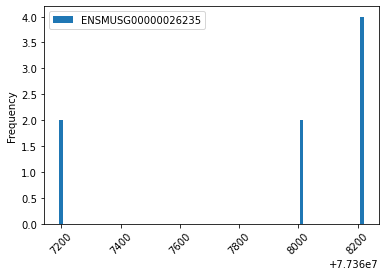

In [39]:
new_df = pd.DataFrame(maps['read_start_position'][5], columns=[maps.index[5]])
plot=new_df.plot.hist(bins=90, rot=45)